# [Lab Session 3](fourier.ipynb)


In [121]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.transform import resize

**[Task 1 (a).]()** Load the first image, resize it to (256, 256) and display it.


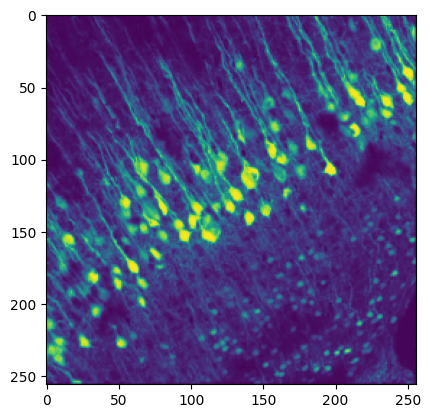

In [122]:
cell_img = plt.imread('data/cells.png')
cell_img_res = resize(cell_img, [256,256])
plt.imshow(cell_img_res)

**[Task 1 (b).]()** Apply the fast Fourier transform and check the data type of the result.


In [123]:
cell_ft = np.fft.fft2(cell_img)
cell_ft.dtype
amplitude = np.abs(cell_ft)
phase = np.angle(cell_ft)


**[Task 1 (c).]()** Extract the phase and amplitude and display them.


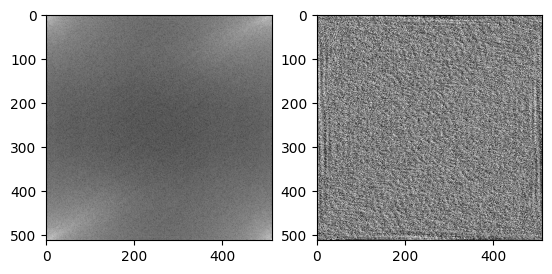

In [124]:
amplitude = np.abs(cell_ft)
phase = np.angle(cell_ft)

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase, 'gray')

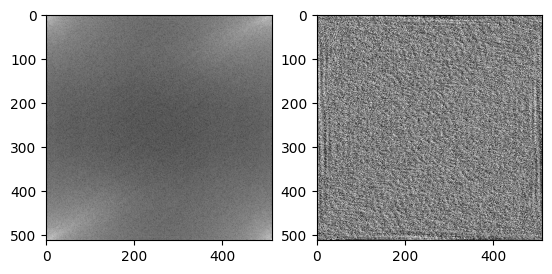

In [125]:
plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase, 'gray')

**[Task 1 (d).]()** Do a shift so that zero is displayed in the center of the image and show amplitude and phase again.


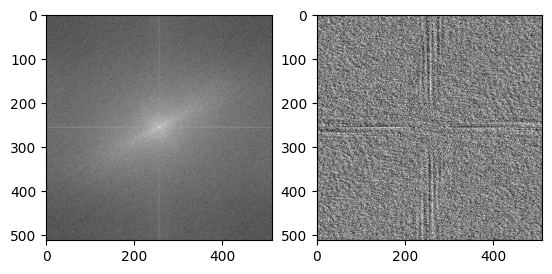

In [126]:
cell_ft_2 = np.fft.fftshift(cell_ft)
amplitude = np.abs(cell_ft_2)
phase = np.angle(cell_ft_2)

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase, 'gray')

**[Task 1 (e).]()** Apply the inverse FFT and display the restored image.


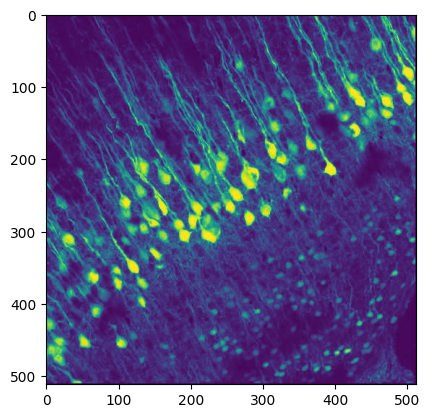

In [127]:
restored = np.fft.ifft2 (np.fft.ifftshift (cell_ft_2)).real
plt.imshow (restored)

---


**[Task 2 (a).]()** Load the brain MR image.


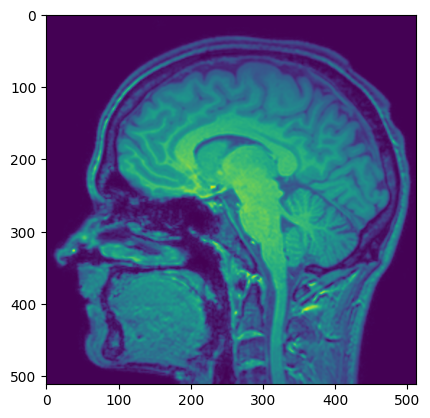

In [128]:
brain_img = plt.imread ('data/brain_mri.png')
brain_img = resize(brain_img, cell_img.shape)
plt.imshow(brain_img)

**[Task 2 (b).]()** Apply the FFT, do a shift, extract amplitude and phase.


In [129]:
brain_shift = np.fft.fftshift(np.fft.fft2(brain_img))
brain_amp = np.abs(brain_shift) 
brain_phase = np.angle(brain_shift)

In [130]:
def to_complex_array(amplitude_array, phase_array):
    return amplitude_array * np.exp(1j * phase_array)

**[Task 2 (c).]()** Merge the amplitude of the brain MR image and the phase of cell image. Do the IFFT and display the resulting image.


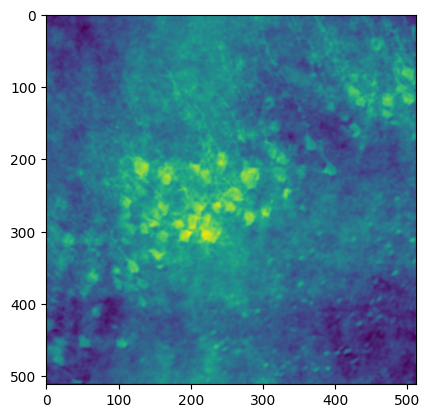

In [131]:
merged_1 = to_complex_array (brain_amp, phase)
plt.imshow (np.fft.ifft2(np.fft.ifftshift(merged_1)).real)

**[Task 2 (d).]()** Repeat this with the amplitude of the cells and the phase of the brain.


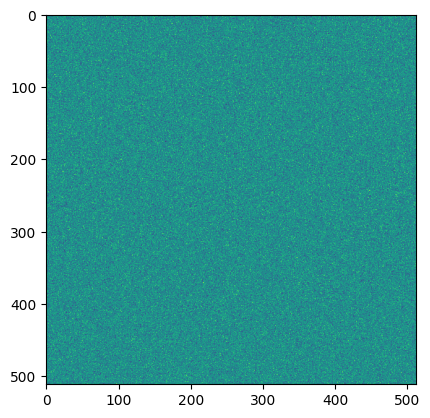

In [132]:
merged_2 = to_complex_array (brain_phase, amplitude)
plt.imshow (np.fft.ifft2(np.fft.ifftshift(merged_2)).real)

---


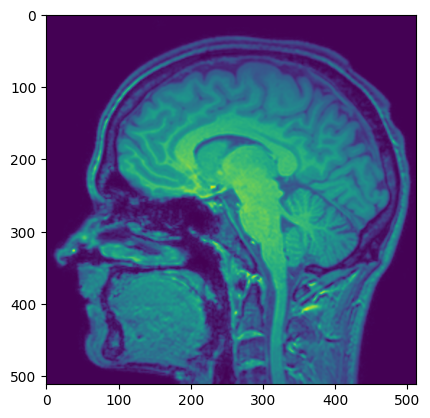

In [133]:
brain_mri = plt.imread('data/brain_mri.png')
brain_mri = resize(brain_mri, cell_img.shape)
plt.imshow (brain_mri)

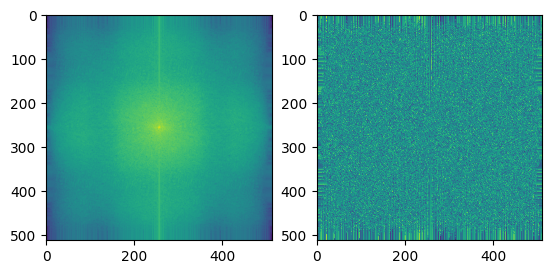

In [134]:
brain_mr_fft = np.fft.fftshift(np.fft.fft2(brain_mri))
amp_b = np.abs(brain_mr_fft)
phs_b = np.angle(brain_mr_fft)

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amp_b))
plt.subplot(1, 2, 2)
plt.imshow(phs_b)

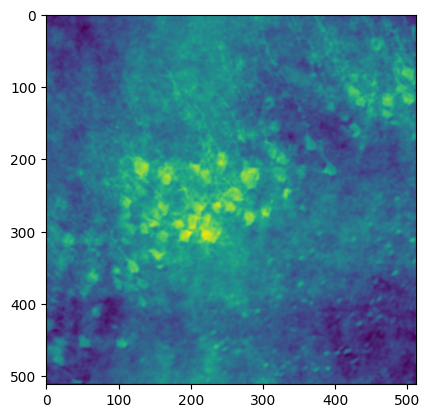

In [135]:
composed_1 = to_complex_array (amp_b, phase)
plt.imshow (np.fft.ifft2(np.fft.ifftshift(composed_1)).real)

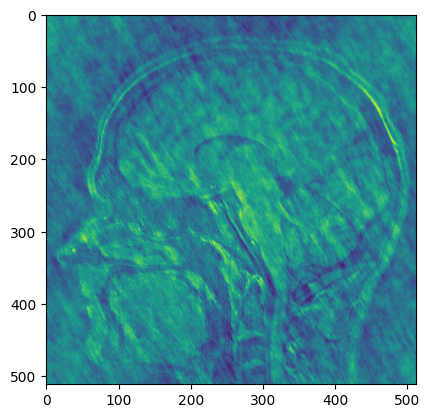

In [136]:
composed_2 = to_complex_array (amplitude, phs_b)
plt.imshow (np.fft.ifft2(np.fft.ifftshift(composed_2)).real)

The phase carries more information about the recognizable structure of an image than the amplitude. The phase preserves the spatial arrangement of image features, such as edges, shapes, and object positions, whereas the amplitude describes the strength of the spatial frequency components.

**[Task 3 (a).]()** Create a lowpass filter mask.


In [137]:
filter_window_size = 50
array = np.zeros (brain_mri.shape)
cy,cx = np.array(array.shape) // 2
r = 25
array[cy-r:cy+r, cx-r:cx+r] = 1


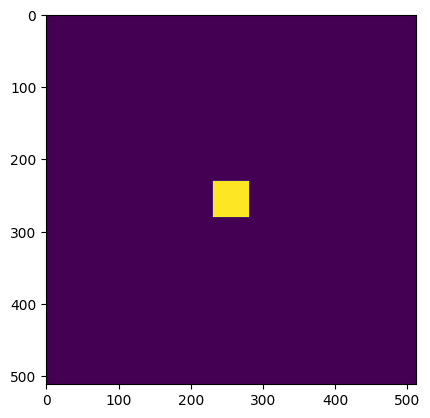

In [138]:
plt.imshow(array)

**[Task 3 (b).]()** Create a highpass filter maks.


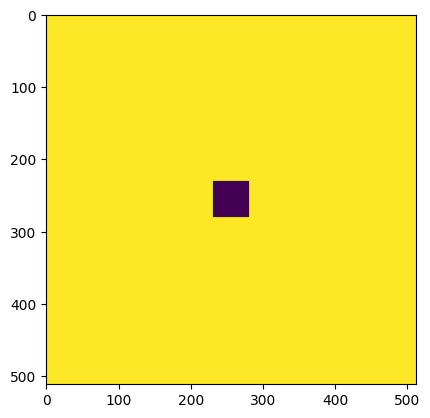

In [139]:
high = 1 - array
plt.imshow (high)

**[Task 3 (c).]()** Apply the lowpass and highpass filter mask to the amplitude of the brain and display the results.


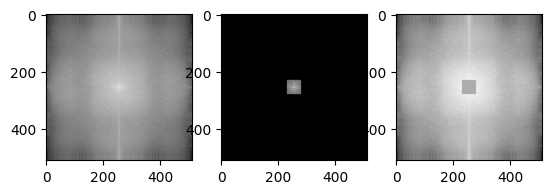

In [140]:
plt.figure()
plt.subplot(1, 3, 1)
plt.imshow(np.log(amp_b), 'gray')
plt.subplot(1, 3, 2)
plt.imshow(np.log(amp_b)*array, 'gray')
plt.subplot(1, 3, 3)
plt.imshow(np.log(amp_b)*high, 'gray')

**[Task 3 (d).]()** Apply the mask to the amplitude, merge the result with the phase and restore the image.


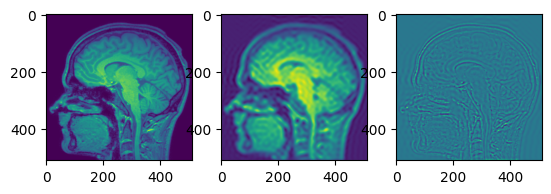

In [141]:
merged_3 = to_complex_array (amp_b*array, phs_b)
merged_4 = to_complex_array (amp_b*high, phs_b)
merged_5 = to_complex_array (amp_b, phs_b)

plt.figure()
plt.subplot(1, 3, 1)
plt.imshow (np.fft.ifft2(np.fft.ifftshift(merged_5)).real)
plt.subplot(1, 3, 2)
plt.imshow (np.fft.ifft2(np.fft.ifftshift(merged_3)).real)
plt.subplot(1, 3, 3)
plt.imshow (np.fft.ifft2(np.fft.ifftshift(merged_4)).real)

---


**[Task 4 (a).]()** Implement a function that computes the 2D-DFT.


In [142]:

def my_dft (img):
    dft = np.zeros(img.shape, dtype=complex)
    M, N = img.shape
    for u in range (M):
        for v in range(N):            
            for x in range(M):                
                for y in range(N):                    
                    dft [u, v] += img[x, y] * np.exp(-2j * np.pi * (u*x/M + v*y/N))    
    return dft / (M * N)


**[Task 4 (b).]()** Implement a function that computes the 2D-IDFT.


In [143]:
def my_idft (dft):
    idft = np.zeros(dft.shape, dtype=complex)
    M, N = dft.shape
    for u in range (M):
        for v in range(N):            
            for x in range(M):                
                for y in range(N):                    
                    idft[u, v] += dft[x, y] * np.exp(2j * np.pi * (u*x/M + v*y/N))    
    return idft.real

Due to high computational costs, we need to resize the image.


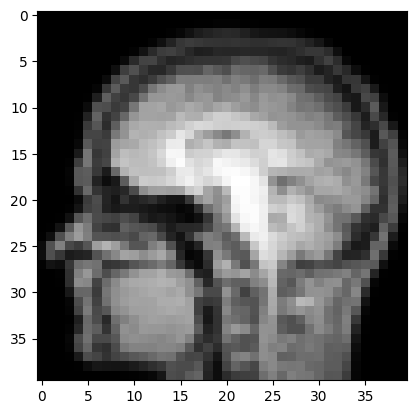

In [144]:
test_img = resize(brain_img, (40, 40))
plt.imshow(test_img, 'gray')

**[Task 4 (c).]()** Apply your DFT implementation to the image and display amplitude and phase.


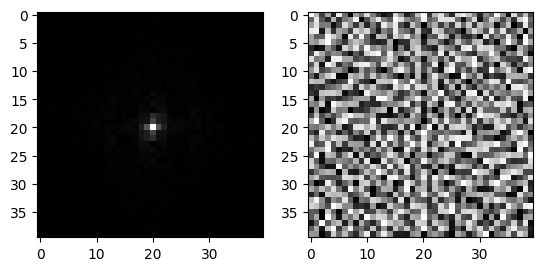

In [145]:
mydft = my_dft (test_img)
amplitude = np.fft.fftshift(np.abs(mydft))
phase = np.fft.fftshift(np.angle(mydft))

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(amplitude,'gray')

plt.subplot(1, 2, 2)
plt.imshow(phase,'gray')

**[Task 4 (d).]()** Reconstruct the image using your IDFT implementation and display it.


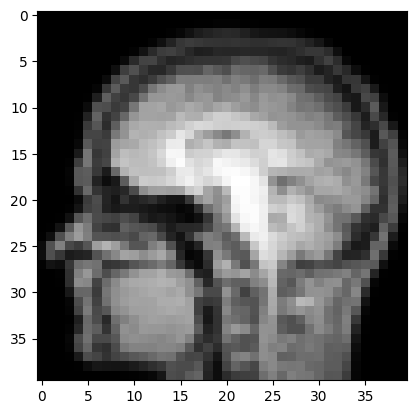

In [150]:
plt.imshow(my_idft(mydft),'gray')

**[Task 4 (e).]()** Compare your result to the result of numpy's FFT


In [155]:
mydft = my_dft(test_img)
np_fft = np.fft.fft2(test_img, norm='forward')

print((mydft == np_fft).all())



False


**[Task 4 (f).]()** Round the arrays and compare them again.


In [154]:
print(np.mean(np.abs(mydft - np_fft)))

own_dft = np.round(mydft, 5)
np_fft = np.round(np_fft, 5)

print((own_dft == np_fft).all())

7.499126738797286e-17
True


**[Task 4 (g).]()** Compare the run times of the two algorithms (your DFT and numpy's FFT)


In [153]:
%timeit my_dft(test_img)
%timeit np.fft.fft2(test_img, norm='forward')

KeyboardInterrupt: 